# Task 2: Exploratory Data Analysis (EDA) - Online Retail

**Objective:** Explore the cleaned Online Retail dataset to understand its distributions, relationships, time trends, and customer/product/country behavior, and to derive business insights.

**Input:** `cleaned_online_retail.csv` (output of Task 1)

## Step 1: Load and Inspect

**What:** Load the cleaned dataset and confirm its structure.

**Why:** Before any analysis, we must verify that the file loaded correctly (shape, data types, no unexpected nulls). Parsing `invoice_date` as datetime now is necessary for time-series analysis later, and reading `customer_id` as text prevents it from being treated as a number.

In [19]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean default plot style
sns.set_theme(style="whitegrid")

# Load the cleaned dataset
df = pd.read_csv(
    "cleaned_online_retail.csv",
    dtype={"customer_id": str},        # keep IDs as text
    parse_dates=["invoice_date"]       # parse dates as datetime
)

# Basic structure checks
print("Shape:", df.shape)
print("Total null values:", df.isnull().sum().sum())
df.info()
df.head()

Shape: (531201, 15)
Total null values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 531201 entries, 0 to 531200
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   invoice_no              531201 non-null  object        
 1   stock_code              531201 non-null  object        
 2   description             531201 non-null  object        
 3   quantity                531201 non-null  int64         
 4   invoice_date            531201 non-null  datetime64[ns]
 5   unit_price              531201 non-null  float64       
 6   customer_id             531201 non-null  object        
 7   country                 531201 non-null  object        
 8   is_missing_customer     531201 non-null  bool          
 9   total_price             531201 non-null  float64       
 10  is_cancelled            531201 non-null  bool          
 11  is_outlier_quantity     531201 non-null  bool     

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_missing_customer,total_price,is_cancelled,is_outlier_quantity,is_outlier_unit_price,is_outlier_total_price,is_outlier_any
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,15.30,False,False,False,False,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False,False,False,False,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,22.00,False,False,False,False,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False,False,False,False,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False,False,False,False,False


**Observations (Step 1)**
- The cleaned dataset loaded correctly with **531,201 rows and 15 columns**, matching the Task 1 export.
- There are **0 null values**, so no further missing-value handling is needed before analysis.
- `invoice_date` is parsed as `datetime64[ns]`, so time-based analysis (monthly/hourly trends) is possible.
- The 6 flag columns (`is_missing_customer`, `is_cancelled`, and the four `is_outlier_*` columns) are stored as `bool`.
- `customer_id` is stored as text (object), which is correct because missing customers are labelled "Unknown".
- The first rows show a valid sale: quantity 6 x unit price 2.55 = total price 15.30, confirming that `total_price` was calculated correctly.


## Step 2: Descriptive Statistics

**What:** Compute summary statistics (count, mean, std, min, quartiles, percentiles, max, skewness) for the numeric columns, and frequency summaries (unique values, most frequent value) for the categorical columns.

**Why:** Descriptive statistics give a first numeric picture of the data: typical values, spread, extremes, and how skewed the distributions are. We analyse **genuine sales only** (non-cancelled rows), because cancelled rows are returns with negative quantities and would distort averages. Cancelled rows are examined separately.

In [20]:
# Split genuine sales and cancelled rows (returns)
genuine = df[~df["is_cancelled"]].copy()
cancelled = df[df["is_cancelled"]].copy()
print("Genuine sales rows:", genuine.shape[0])
print("Cancelled rows:", cancelled.shape[0])

# Descriptive statistics for the main numeric columns
num_cols = ["quantity", "unit_price", "total_price"]
stats = genuine[num_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T

# Add skewness to measure asymmetry of each distribution
stats["skew"] = genuine[num_cols].skew()
stats.round(2)

Genuine sales rows: 522535
Cancelled rows: 8666


,count,mean,std,min,25%,50%,75%,95%,99%,max,skew
quantity,522535.0,10.35,37.85,1.00,1.00,4.00,12.00,30.00,100.00,4800.0,33.39
unit_price,522535.0,3.27,4.39,0.04,1.25,2.08,4.13,9.95,16.63,649.5,25.73
total_price,522535.0,19.14,84.67,0.06,3.90,9.90,17.70,59.40,179.00,38970.0,200.81


**Observations (Step 2A: numeric columns, genuine sales only, 522,535 rows)**
- All three numeric columns are **strongly right-skewed**: skewness is 33.39 (quantity), 25.73 (unit_price) and 200.81 (total_price). A skewness near 0 would indicate a symmetric distribution.
- In every case the **mean is well above the median**: quantity 10.35 vs 4, unit_price 3.27 vs 2.08, total_price 19.14 vs 9.90. A small number of very large values pulls the mean up, so the median is the better measure of a "typical" order.
- The **standard deviation is larger than the mean** for all three columns (for example total_price: std 84.67 vs mean 19.14), which confirms very high variability.
- A typical order line is small: the median is **4 units** at a median unit price of **2.08**, giving a median line value of **9.90**. Half of all order lines have a total value between roughly 3.90 and 17.70 (25th to 75th percentile).
- The upper tail is extreme: the 99th percentile of total_price is 179.00, while the maximum is 38,970.00 before correction: see step 2D(about 218 times larger). The same pattern appears in quantity (99th percentile 100 vs maximum 4,800). These extreme rows need to be inspected before deciding how to treat them.
- The minimum unit_price is 0.04 and the minimum total_price is 0.06, consistent with the cleaning rules from Task 1 (no zero or negative values among genuine sales).Values before correction; see Step 2D and Step 2E.

In [21]:
# Summary of categorical (text) columns
cat_cols = ["invoice_no", "stock_code", "description", "customer_id", "country"]
genuine[cat_cols].describe()

,invoice_no,stock_code,description,customer_id,country
count,522535,522535,522535,522535,522535
unique,19771,3906,4011,4334,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,Unknown,United Kingdom
freq,1112,2253,2311,131387,478869


**Observations (Step 2B: categorical columns, genuine sales)**
- The genuine sales contain **19,771 unique invoices**, 3,906 stock codes, 4,011 product descriptions, 4,334 customer IDs (including the "Unknown" label) and 38 countries.
- On average an invoice has about **26 order lines** (522,535 / 19,771). The largest invoice, 573585, has 1,112 lines, so some customers place very large mixed orders.
- The **United Kingdom** accounts for 478,869 order lines (**91.6%**), so the dataset is heavily UK-centred and other countries have small samples.
- **25.1% of order lines (131,387)** have no customer ID ("Unknown"). Customer-level analysis must exclude them.
- The most frequent product by number of order lines is **WHITE HANGING HEART T-LIGHT HOLDER** (stock code 85123A, 2,253 lines). Its description appears in 2,311 lines, so the same description is attached to more than one stock code. Also, there are more descriptions (4,011) than stock codes (3,906), so some codes carry more than one description.
- "Most frequent" here means most order lines, not most units sold or highest revenue. Revenue-based rankings are done in the group-by section.


### Step 2C: Inspect the Largest Orders

**What:** Display the 5 largest genuine order lines by `total_price` and by `quantity`.

**Why:** The maximum values (total_price 38,970.00, quantity 4,800) are far above the 99th percentile. Before treating them as real wholesale orders, we must check what products they are and whether they look like genuine bulk purchases or special entries (for example fees or adjustments).

In [22]:
# Show the 5 largest order lines by total value and by quantity
cols_to_show = ["invoice_no", "stock_code", "description", "quantity", "unit_price", "total_price", "country"]

print("Top 5 by total_price:")
display(genuine.nlargest(5, "total_price")[cols_to_show])

print("Top 5 by quantity:")
display(genuine.nlargest(5, "quantity")[cols_to_show])

Top 5 by total_price:


,invoice_no,stock_code,description,quantity,unit_price,total_price,country
218136,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
341671,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,United Kingdom
51605,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
157219,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
413492,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00,Netherlands


Top 5 by quantity:


,invoice_no,stock_code,description,quantity,unit_price,total_price,country
413523,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00,United Kingdom
201902,554868,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00,United Kingdom
95501,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92,United Kingdom
265489,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16,United Kingdom
51605,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom


**Observations (Step 2C: largest orders)**
- The largest **quantities** (4,800 / 4,300 / 3,906 / 3,186 / 3,114) all belong to very low-priced items (unit price 0.06 to 0.82), which is consistent with genuine wholesale purchases. A large quantity does not imply large revenue: 3,186 balm tins at 0.06 give only 191.16.
- Most of the largest **total_price** lines (7,144.72; 6,539.40; 4,992.00) are plausible bulk orders of everyday products.
- The single largest line (invoice 556444, total 38,970.00) is only 60 pieces at a unit price of 649.50. That unit price is the maximum in the dataset, far above the 99th percentile (16.63), so this line is not a bulk-quantity order and needs verification before it is treated as genuine revenue.
- The same product (FAIRY CAKE FLANNEL ASSORTED COLOUR, 3,114 units at 2.10) appears in two different invoices (540815 and 550461). They are not exact duplicates, so they are kept as repeat orders.

### Step 2D: Verify the Largest Order Line

**What:** Search the cancelled rows for a reversal that matches the largest genuine order line (stock code 22502, quantity -60, unit price 649.50).

**Why:** If this sale was cancelled, it does not represent real revenue and would distort the mean, the correlation matrix and the scatter plots. If no reversal exists, the line stays in the analysis.

In [23]:
# Look for a cancellation matching the largest order (same product, quantity and unit price)
match = cancelled[
    (cancelled["stock_code"] == "22502")
    & (cancelled["quantity"] == -60)
    & (cancelled["unit_price"] == 649.5)
]
display(match[["invoice_no", "stock_code", "description", "quantity", "unit_price", "invoice_date", "customer_id"]])

# Show the original order line for comparison
display(genuine.loc[[218136], ["invoice_no", "invoice_date", "customer_id", "quantity", "unit_price", "total_price"]])

,invoice_no,stock_code,description,quantity,unit_price,invoice_date,customer_id


,invoice_no,invoice_date,customer_id,quantity,unit_price,total_price
218136,556444,2011-06-10 15:28:00,15098,60,649.5,38970.0


**Observations (Step 2D: matching cancellation search)**
- The search for a cancelled row with the same stock code (22502), quantity (-60) and unit price (649.50) returned **no rows** in the cleaned dataset.
- The original line is confirmed: invoice 556444, customer 15098, quantity 60, unit price 649.50, total 38,970.00, placed on 2011-06-10 at 15:28.
- An empty result does not prove that the sale was genuine. A reversal can be recorded as a different entry type (for example a manual adjustment with a different stock code), and such non-product cancelled rows were removed during Task 1. The next step therefore searches the rows removed in Task 1.

### Step 2D: Verification Result and Correction

**Finding:** The largest genuine order line (invoice 556444, customer 15098, quantity 60, unit price 649.50, total 38,970.00, 2011-06-10 15:28) was reversed three minutes later by a manual cancellation entry (invoice C556445, stock code "M", quantity -1, unit price 38,970.00, same customer). This reversal had been removed in Task 1 as a non-product row, but the original sale had remained in the cleaned data.

**Action:** This single order line is removed from the genuine sales used for the analysis, because it does not represent real revenue and would distort the maximum, the scatter plots and the correlations.

In [24]:
# Remove the reversed sale (invoice 556444, stock code 22502) from the genuine sales
before = genuine.shape[0]
genuine = genuine[~((genuine["invoice_no"] == "556444") & (genuine["stock_code"] == "22502"))].copy()

print("Rows removed:", before - genuine.shape[0])
print("Genuine rows now:", genuine.shape[0])
print("New max total_price:", genuine["total_price"].max())
print("New mean total_price:", round(genuine["total_price"].mean(), 2))

Rows removed: 1
Genuine rows now: 522534
New max total_price: 7144.719999999999
New mean total_price: 19.07


**Observations (Step 2D correction)**
- Exactly **1 row** was removed, leaving **522,534** genuine order lines.
- The maximum `total_price` fell from 38,970.00 to **7,144.72**, so the largest value is now about 5.4 times smaller. The earlier maximum was a single reversed sale and a clear distortion.
- The mean `total_price` moved only from 19.14 to **19.07**, because one row out of more than 500,000 has a small effect on the mean. The effect on the maximum, the skewness and the standard deviation is much larger.
- All later analysis (distributions, correlations, group-by, scatter plots) uses this corrected `genuine` table.

### Step 2E: Descriptive Statistics After Correction

**What:** Recompute the numeric summary on the corrected genuine sales table.

**Why:** Step 2A was computed before the reversed sale was removed. These are the final statistics used for the rest of the analysis.

In [25]:
# Recompute descriptive statistics on the corrected genuine sales
stats_final = genuine[num_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T
stats_final["skew"] = genuine[num_cols].skew()
stats_final.round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew
quantity,522534.0,10.35,37.85,1.00,1.00,4.00,12.00,30.00,100.00,4800.00,33.39
unit_price,522534.0,3.27,4.30,0.04,1.25,2.08,4.13,9.95,16.63,649.50,20.93
total_price,522534.0,19.07,65.31,0.06,3.90,9.90,17.70,59.40,179.00,7144.72,31.55


**Observations (Step 2E: corrected statistics, 522,534 rows)**
- After removing the reversed sale, the **maximum total_price is 7,144.72** (was 38,970.00) and the **skewness of total_price fell from 200.81 to 31.55**. The standard deviation fell from 84.67 to 65.31. One reversed line was responsible for most of the extreme tail.
- The distributions remain **strongly right-skewed**: skewness is 33.39 (quantity), 20.93 (unit_price) and 31.55 (total_price). In all three columns the mean is well above the median (quantity 10.35 vs 4, unit_price 3.27 vs 2.08, total_price 19.07 vs 9.90), so the median describes a typical order line better.
- The 99th percentile of total_price is 179.00, while the maximum is 7,144.72, about 40 times larger. Extreme bulk orders still exist, but they are now plausible wholesale lines rather than a data artefact.
- The quantity statistics did not change (mean 10.35, median 4, maximum 4,800) because the removed line had only 60 units.
- The maximum unit_price is still 649.50. Step 2F shows that this belongs to a single legitimate sale (quantity 1) of the same product, so it is a genuine high-priced item and not an error.
- These corrected statistics replace those in Step 2A (computed before the correction).

In [26]:
# Check which rows still have the maximum unit price
display(genuine[genuine["unit_price"] >= 649][["invoice_no", "stock_code", "description", "quantity", "unit_price", "total_price", "invoice_date"]])

,invoice_no,stock_code,description,quantity,unit_price,total_price,invoice_date
218137,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,649.5,2011-06-10 15:33:00


**Observations (Step 2F: remaining rows with the maximum unit price)**
- Only **one** line still has a unit price of 649.50: invoice 556446, stock code 22502 (PICNIC BASKET WICKER 60 PIECES), quantity 1, total 649.50, placed on 2011-06-10 at 15:33.
- This is the same product as the reversed sale, so **649.50 is the normal price of this item**. The price itself is not an error; the anomaly in the removed line was its quantity of 60.
- The sequence on that day (60 units at 15:28, a full reversal at 15:31, one unit at 15:33) is consistent with an order entered with a wrong quantity and then corrected. The data alone does not prove this, so it is noted only as the likely explanation.
- The remaining 649.50 line is a genuine sale and is kept. The unit_price maximum of 649.50 in Step 2E is therefore a legitimate high-priced product, not an outlier error.

## Step 3: Distributions (Histograms and KDE Plots)

**What:** Plot histograms with KDE (kernel density estimate) curves for `quantity`, `unit_price` and `total_price`. The top row uses the raw scale, clipped at the 99th percentile. The bottom row uses a log10 scale with all values.

**Why:** These columns are extremely right-skewed (Step 2E), so a plain histogram would show one tall bar near zero and hide the shape of the data. Clipping at the 99th percentile shows the typical range, and the log scale shows the whole range including the extreme values.

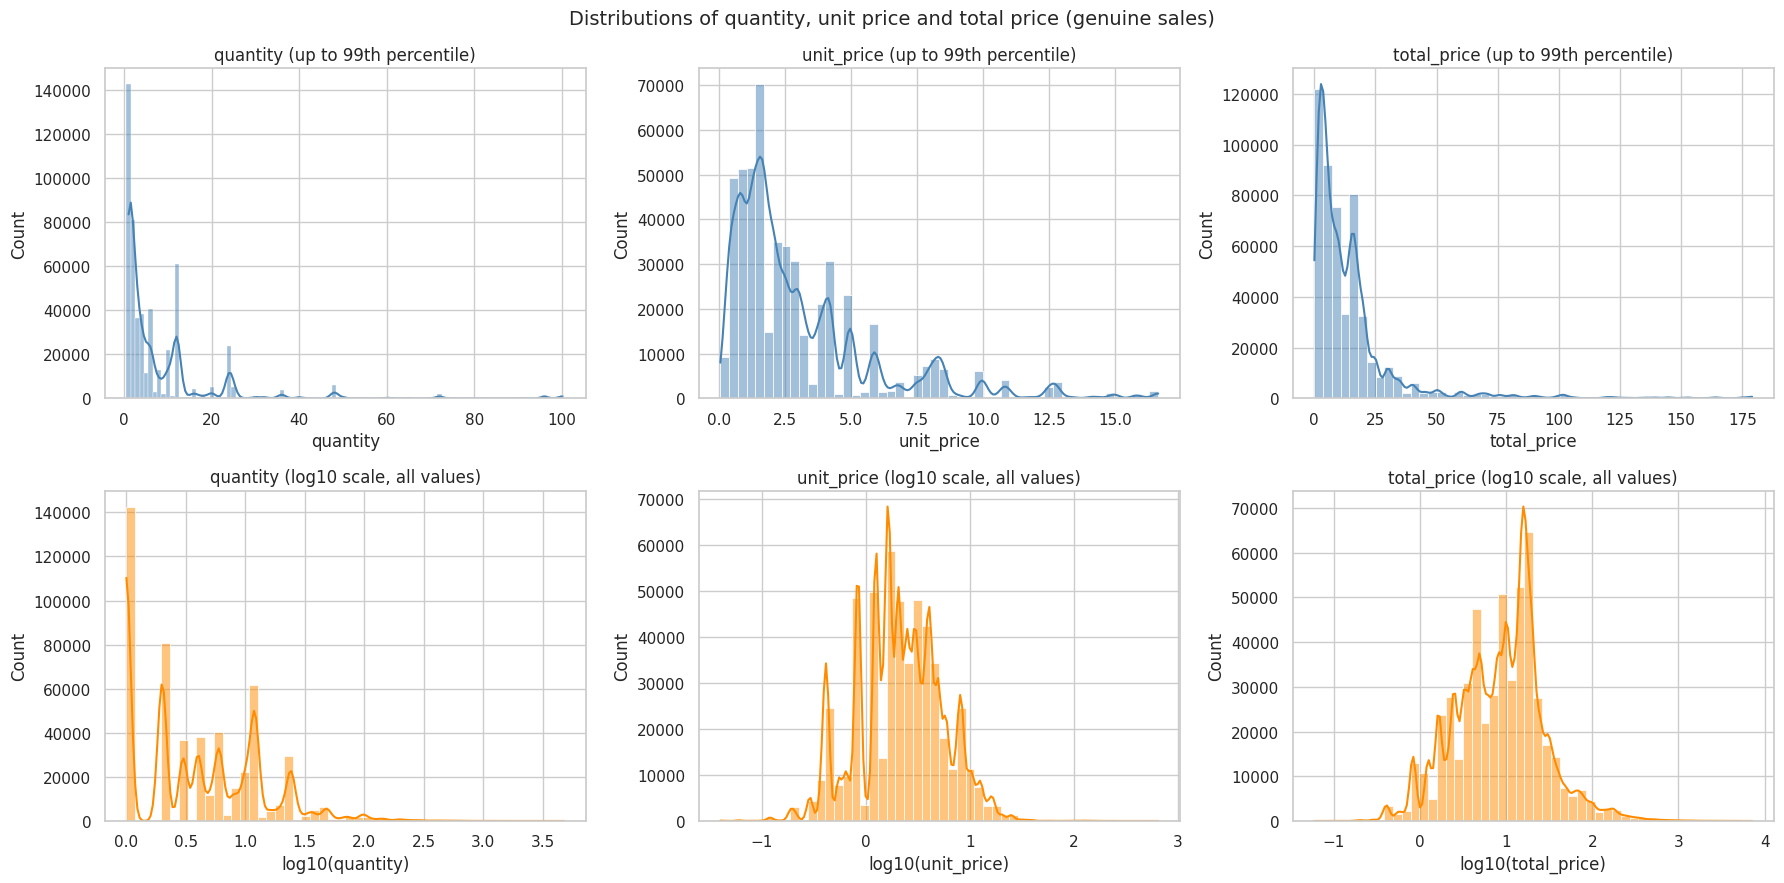

In [27]:
# Histograms with KDE for the three numeric columns (genuine sales only)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for i, col in enumerate(num_cols):
    # Row 1: raw scale, values up to the 99th percentile
    upper = genuine[col].quantile(0.99)
    sns.histplot(
        genuine.loc[genuine[col] <= upper, col],
        bins=50, kde=True, discrete=(col == "quantity"),
        ax=axes[0, i], color="steelblue"
    )
    axes[0, i].set_title(f"{col} (up to 99th percentile)")
    axes[0, i].set_xlabel(col)

    # Row 2: log10 scale, all values
    sns.histplot(np.log10(genuine[col]), bins=50, kde=True, ax=axes[1, i], color="darkorange")
    axes[1, i].set_title(f"{col} (log10 scale, all values)")
    axes[1, i].set_xlabel(f"log10({col})")

plt.suptitle("Distributions of quantity, unit price and total price (genuine sales)", fontsize=14)
plt.tight_layout()
plt.show()

**Observations (Step 3: distributions)**
- **quantity:** The distribution is dominated by very small order lines. A quantity of 1 is by far the most common value (about 140,000 lines in the top-left histogram). Smaller spikes appear at round pack sizes such as 12 and 24 (and smaller ones near 6, 48 and 100), which suggests that many products are sold in standard multiples, so quantity is not a smooth continuous variable.
- **unit_price:** Most prices fall between about 1 and 5, with the highest peak around 1.25 to 2. There are smaller peaks near 5, 8, 10 and 12.5, which look like common retail price points. The right tail is long but thin.
- **total_price:** Most order lines are worth less than about 25, with the peak close to zero and a thin tail up to the 99th percentile (179).
- **Log scale (bottom row):** After the log10 transformation, unit_price and total_price look much closer to a symmetric, bell-shaped curve (unit_price centred near 10^0.3, about 2; total_price centred near 10^1, about 10). This confirms that the raw variables are right-skewed in a roughly multiplicative way, and that a log transformation is a sensible option for modelling in Task 3 (especially for the target `total_price`).
- The quantity histogram stays spiky even on the log scale, because quantity takes only whole numbers.
- The top-row charts are cut at the 99th percentile, so they show the typical range only; the bottom row includes all values.


## Step 4: Correlation Analysis

**What:** Compute the correlation matrix of the numeric columns, plus three time features derived from `invoice_date` (month, hour, day of week), and show it as a heatmap with both Pearson and Spearman correlations.

**Why:** Correlation shows which variables move together and guides feature selection in Task 3. Pearson measures linear relationships but is sensitive to extreme values. Spearman uses ranks, so it is more reliable for highly skewed data like ours. Comparing the two shows how much the extreme values influence the result.

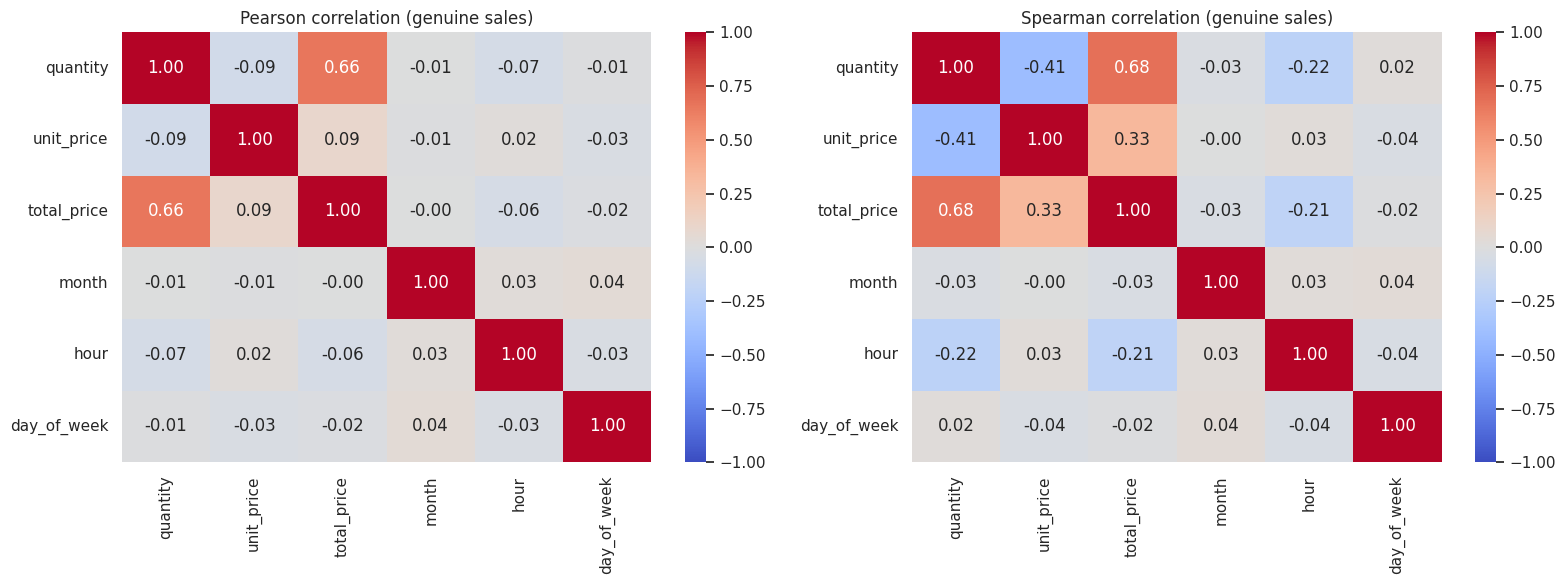

In [28]:
# Derive simple time features from the invoice date
genuine["month"] = genuine["invoice_date"].dt.month
genuine["hour"] = genuine["invoice_date"].dt.hour
genuine["day_of_week"] = genuine["invoice_date"].dt.dayofweek   # Monday = 0

corr_cols = ["quantity", "unit_price", "total_price", "month", "hour", "day_of_week"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = genuine[corr_cols].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation (genuine sales)")

plt.tight_layout()
plt.show()

**Observations (Step 4: correlation heatmap)**
- **quantity and total_price** are strongly positively correlated (Pearson 0.66, Spearman 0.68). **unit_price and total_price** are weakly correlated (Pearson 0.09, Spearman 0.33). Since `total_price = quantity x unit_price`, these relationships are partly built in by definition. This is important for Task 3: using `quantity` and `unit_price` as features to predict `total_price` would cause data leakage, so the features must be chosen differently.
- Pearson and Spearman give different answers for **quantity vs unit_price**: Pearson is -0.09 (almost none), while Spearman is **-0.41** (moderate negative). Rank-based correlation shows a clear pattern that a few extreme values hide in the Pearson result: **cheaper products tend to be bought in larger quantities**.
- The same effect appears for unit_price vs total_price (0.09 vs 0.33): extreme values weaken the Pearson figure, so Spearman is the more reliable measure for this skewed data.
- **hour** has a small negative Spearman correlation with quantity (-0.22) and total_price (-0.21), which suggests that order lines placed earlier in the day tend to be somewhat larger. This is only a hint and is checked in the group-by analysis.
- **month** and **day_of_week** are close to zero with every variable (between -0.04 and 0.04). This only means there is no linear relationship at the level of individual order lines. It does not rule out seasonal patterns in total revenue or in the number of orders, which are examined in the time-trend step. Month and day of week are also cyclic categories, so a linear correlation is a weak tool for them.

## Step 5: Box Plots by Category

**What:** Compare the distribution of `total_price` across the six countries with the most order lines, and across the 12 months.

**Why:** Box plots show the median, spread and outliers of each group side by side. The y-axis uses a log scale because `total_price` is extremely right-skewed; on a normal scale every box would be squeezed flat. Comparing groups shows whether typical order value differs by market or season.

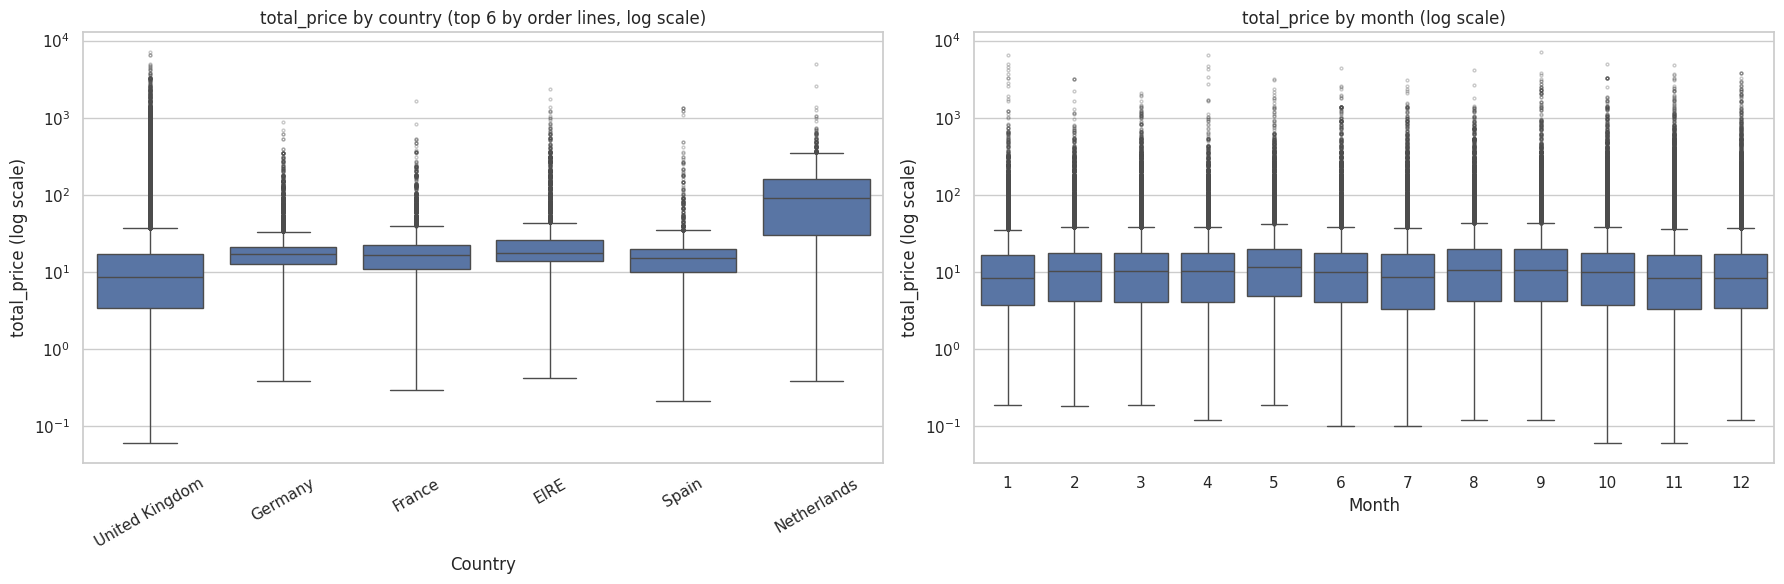

In [29]:
# Box plots of total_price by country (top 6) and by month, log scale
top_countries = genuine["country"].value_counts().head(6).index
subset = genuine[genuine["country"].isin(top_countries)]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.boxplot(
    data=subset, x="country", y="total_price", order=top_countries,
    ax=axes[0], flierprops={"markersize": 2, "alpha": 0.3}
)
axes[0].set_yscale("log")
axes[0].set_title("total_price by country (top 6 by order lines, log scale)")
axes[0].set_xlabel("Country")
axes[0].set_ylabel("total_price (log scale)")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(
    data=genuine, x="month", y="total_price",
    ax=axes[1], flierprops={"markersize": 2, "alpha": 0.3}
)
axes[1].set_yscale("log")
axes[1].set_title("total_price by month (log scale)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("total_price (log scale)")

plt.tight_layout()
plt.show()

**Observations (Step 5: box plots by category, log scale)**
- **By country:** The typical order line value differs clearly between markets. The United Kingdom has the lowest median (about 9) and by far the widest spread, with whiskers reaching from below 0.1 to about 40 and outliers up to several thousand. Germany, France, EIRE and Spain have higher medians (roughly 15 to 18) and much narrower boxes, which means their order lines are more uniform in size.
- **Netherlands** stands out: its median order line (about 90) is roughly ten times the UK median, and even the lower edge of its box (about 30) is above the typical UK order line. Its box plot is also much taller than the other countries, so it has the highest and most variable order values among the six.
- The UK has the most outliers, which is expected because it also has the most order lines (91.6% of the data). More rows make extreme values more likely to appear.
- **By month:** The medians and boxes are almost the same in all 12 months (medians about 8 to 11, boxes roughly 3 to 20). There is **no strong seasonal change in the typical order line value**. Month 5 has a slightly higher box, and months 7 and 11 have slightly lower lower edges, but these differences are small compared with the spread within each month.
- Because the typical line value is stable across months, any seasonal pattern in revenue is more likely to come from the **number of orders** than from the size of each order. This is checked in the next step.
- The Netherlands pattern comes from this chart alone. The number of order lines per country and the customers behind them are not known yet, so it cannot be explained as a wholesale effect without further checking (group-by step).

## Step 6: Time Trends

**What:** Plot monthly revenue and the monthly number of unique invoices as line charts, and total revenue by hour of the day as a bar chart.

**Why:** Step 5 showed that the typical order value is stable across months, so seasonal differences should come from how many orders are placed. Line charts show trends over time, and the hourly bar chart shows when customers buy, which helps with staffing, promotions and the timing of marketing messages. Note that the data ends on 2011-12-09, so the last month is incomplete.

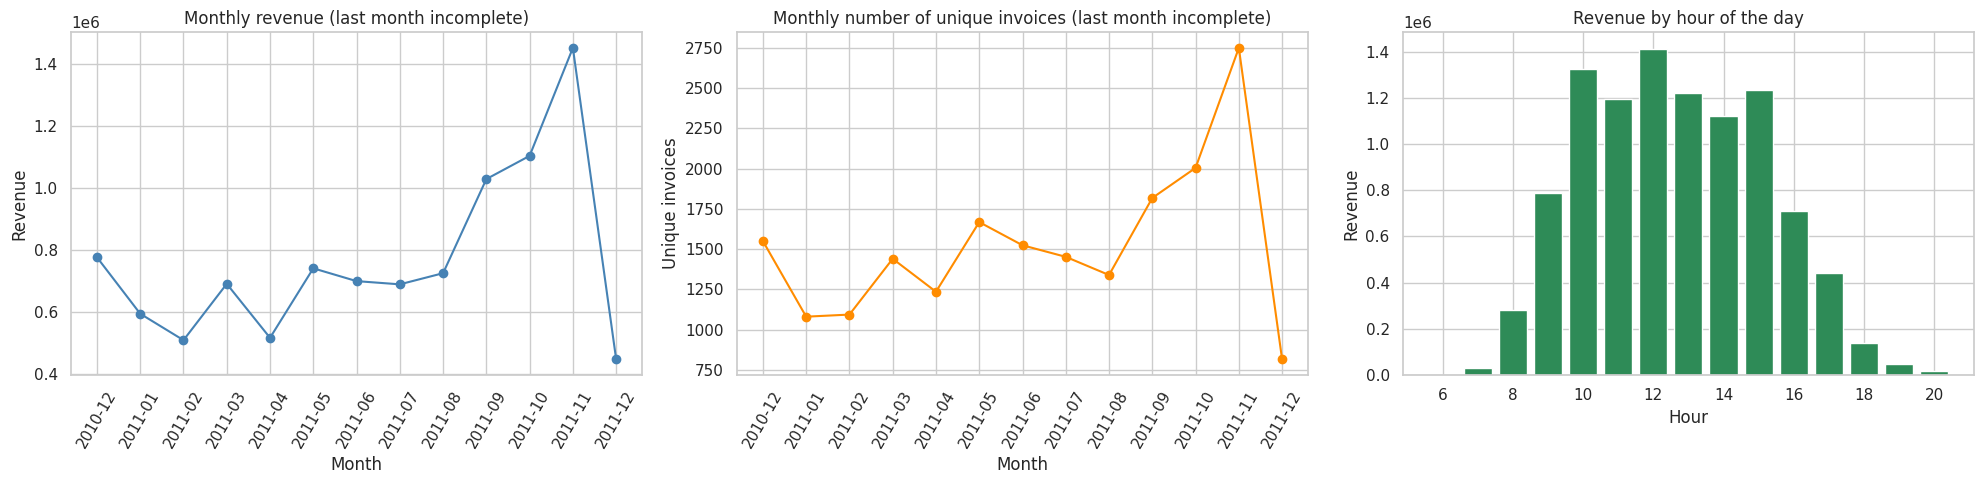

,revenue,orders
year_month,,
2010-12,775638.0,1550
2011-01,593197.0,1080
2011-02,507800.0,1093
2011-03,689834.0,1440
2011-04,515378.0,1235
2011-05,739953.0,1668
2011-06,698589.0,1524
2011-07,688219.0,1452
2011-08,724216.0,1339


In [30]:
# Monthly revenue and number of unique invoices (genuine sales)
genuine["year_month"] = genuine["invoice_date"].dt.to_period("M")
monthly = genuine.groupby("year_month").agg(
    revenue=("total_price", "sum"),
    orders=("invoice_no", "nunique")
)
monthly.index = monthly.index.astype(str)

# Revenue by hour of the day
hourly = genuine.groupby("hour")["total_price"].sum()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(monthly.index, monthly["revenue"], marker="o", color="steelblue")
axes[0].set_title("Monthly revenue (last month incomplete)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")
axes[0].tick_params(axis="x", rotation=60)

axes[1].plot(monthly.index, monthly["orders"], marker="o", color="darkorange")
axes[1].set_title("Monthly number of unique invoices (last month incomplete)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Unique invoices")
axes[1].tick_params(axis="x", rotation=60)

axes[2].bar(hourly.index, hourly.values, color="seagreen")
axes[2].set_title("Revenue by hour of the day")
axes[2].set_xlabel("Hour")
axes[2].set_ylabel("Revenue")

plt.tight_layout()
plt.show()

display(monthly.round(0))

**Observations (Step 6: time trends)**
- **Revenue is clearly seasonal and rises sharply in autumn.** Between January and August 2011 monthly revenue stays in a band of about 0.51M to 0.74M. It then climbs to 1.03M in September, 1.10M in October and **1.45M in November**, the highest month. November revenue is about 2.9 times that of February (the lowest full month, 0.51M).
- **September to November (3 of the 13 months) account for about 36% of total revenue** (3.58M of 9.96M).
- **The rise comes from the number of orders, not from larger orders.** Unique invoices increase from 1,339 in August to 2,751 in November (about 2.1 times). Revenue per invoice (revenue divided by invoices, calculated from the table) stays roughly between 420 and 570 in every month with no upward trend. This agrees with the box plots in Step 5, which showed a stable typical order value across months.
- Revenue and invoice counts move together: the weak months (February and April) and the strong months (May, September to November) are the same in both charts.
- **December 2011 is incomplete** (the data ends on 2011-12-09), so its drop to 446,021 and 815 invoices is not a real decline and must not be compared with full months. December 2010 was a full month (775,638 revenue, 1,550 invoices).
- Because the data covers only about one year, seasonality cannot be separated from general business growth. A gift-season effect before the holidays is a plausible explanation, but this dataset cannot prove it.
- **By hour of the day:** revenue is recorded between about 07:00 and 20:00. It is highest from 10:00 to 15:59 (peak around 12:00), which by reading the bar chart is roughly three quarters of total revenue. It drops quickly after 16:00 and is very low after 18:00. Before 09:00 and after 18:00 there is very little activity.
- The hourly chart shows total revenue, which mostly reflects how many orders are placed in each hour, not the size of individual orders.

## Step 7: Group-by Analysis

**What:** Summarise the genuine sales by country, by product and by customer.

**Why:** The doc requires grouped analysis by category. These tables answer three business questions: which markets bring the revenue, which products sell the most (by revenue and by units), and how concentrated the revenue is among a few customers. Customer-level results exclude the "Unknown" customer label (25.1% of order lines), because these lines cannot be attributed to a specific customer.

In [31]:
# ---- 7A: Country summary ----
country_tbl = genuine.groupby("country").agg(
    revenue=("total_price", "sum"),
    order_lines=("total_price", "size"),
    invoices=("invoice_no", "nunique"),
    median_line_value=("total_price", "median")
)
country_tbl["revenue_share_pct"] = country_tbl["revenue"] / country_tbl["revenue"].sum() * 100
country_tbl["revenue_per_invoice"] = country_tbl["revenue"] / country_tbl["invoices"]
display(country_tbl.sort_values("revenue", ascending=False).head(10).round(2))

,revenue,order_lines,invoices,median_line_value,revenue_share_pct,revenue_per_invoice
country,,,,,,
United Kingdom,8439820.47,478868,17898,8.50,84.72,471.55
Netherlands,283889.34,2322,93,92.16,2.85,3052.57
EIRE,270850.86,7768,282,17.40,2.72,960.46
Germany,205381.15,8643,443,16.95,2.06,463.61
France,184493.00,8085,382,16.50,1.85,482.97
Australia,138103.81,1180,56,66.00,1.39,2466.14
Spain,55706.56,2417,88,15.00,0.56,633.03
Switzerland,53065.60,1927,50,17.70,0.53,1061.31
Japan,37416.37,321,19,70.20,0.38,1969.28


**Observations (Step 7A: country summary, genuine sales)**
- **The United Kingdom dominates revenue:** 8.44M, which is **84.72%** of total revenue, from 17,898 invoices. The next four countries are far behind: Netherlands 2.85%, EIRE 2.72%, Germany 2.06% and France 1.85%. These four together contribute only about 9.5%.
- **The Netherlands is the largest non-UK market, yet it has only 93 invoices.** Its revenue per invoice is about **3,053**, around 6.5 times the UK figure (472), and its median order line is 92.16 compared with 8.50 in the UK. Australia (66.00 median, 2,466 per invoice, 56 invoices) and Japan (70.20 median, 1,969 per invoice, 19 invoices) show the same pattern. These markets consist of **few but very large orders**, which is consistent with bulk or wholesale purchases.
- **EIRE** is a different case: it has more invoices (282) and a moderate value per invoice (960), so its revenue comes from steady repeat ordering rather than a handful of very large orders.
- **Germany and France** have a revenue per invoice (464 and 483) close to the UK (472), but a higher median line value (about 17 vs 8.50). Their invoices contain fewer lines on average (about 20 vs 27 for the UK), with each line larger.
- Because small markets rest on few invoices (Japan: 19, Australia: 56, Netherlands: 93), their numbers depend on a few customers and can change a lot with a single large order. The customer behind these orders has not been checked yet (see Step 7C).
- Revenue is highly concentrated: the UK plus the four largest foreign markets give about 94% of all revenue.

In [32]:
# ---- 7B: Top 10 products by revenue and by units ----
product_tbl = genuine.groupby("stock_code").agg(
    description=("description", lambda s: s.mode().iloc[0]),
    revenue=("total_price", "sum"),
    units=("quantity", "sum")
)
print("Top 10 products by revenue:")
display(product_tbl.sort_values("revenue", ascending=False).head(10).round(2))
print("Top 10 products by units sold:")
display(product_tbl.sort_values("units", ascending=False).head(10).round(2))

Top 10 products by revenue:


,description,revenue,units
stock_code,,,
22423,REGENCY CAKESTAND 3 TIER,174156.54,13851
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641
47566,PARTY BUNTING,99445.23,18283
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
23084,RABBIT NIGHT LIGHT,66870.03,30739
22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329
84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362
79321,CHILLI LIGHTS,54096.36,10302
22197,POPCORN HOLDER,51334.47,56898


Top 10 products by units sold:


,description,revenue,units
stock_code,,,
22197,POPCORN HOLDER,51334.47,56898
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13814.01,54951
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641
21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396
84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362
23084,RABBIT NIGHT LIGHT,66870.03,30739
22492,MINI PAINT SET VINTAGE,16937.82,26633
22616,PACK OF 12 LONDON TISSUES,7975.98,26119


**Observations (Step 7B: top products)**
- The best-selling product by revenue is **REGENCY CAKESTAND 3 TIER** (174,157 revenue, 13,851 units). It sells far fewer units than many other products but has a high unit price (about 12.6 per unit), so its revenue comes from price, not volume.
- The best-selling product by units is **POPCORN HOLDER** (56,898 units, but only 51,334 revenue, about 0.90 per unit). **WORLD WAR 2 GLIDERS** sells 54,951 units for only 13,814 revenue (about 0.25 per unit). Cheap items lead the unit ranking but contribute little revenue, so ranking by units alone would give a misleading picture of what matters commercially.
- Five products appear in both top-10 lists (POPCORN HOLDER, JUMBO BAG RED RETROSPOT, WHITE HANGING HEART T-LIGHT HOLDER, ASSORTED COLOUR BIRD ORNAMENT and RABBIT NIGHT LIGHT). These are reliable "core" products: they combine high volume with high revenue.
- The top 10 products by revenue together bring about **8% of total revenue**, although the catalogue has 3,906 stock codes. Revenue is therefore spread over many products and no single item dominates.
- Several top products look seasonal or party-related (PARTY BUNTING, SPOTTY BUNTING, PAPER CHAIN KIT 50'S CHRISTMAS, CHILLI LIGHTS). This may be linked to the autumn revenue rise in Step 6, but this was not tested here, so it is only a hypothesis.
- Products are grouped by stock code, and the description shown is the most frequent one for that code.

In [33]:
# ---- 7C: Top 10 customers (known customers only) ----
known = genuine[genuine["customer_id"] != "Unknown"]
customer_tbl = known.groupby("customer_id").agg(
    revenue=("total_price", "sum"),
    invoices=("invoice_no", "nunique")
).sort_values("revenue", ascending=False)

top10_share = customer_tbl["revenue"].head(10).sum() / customer_tbl["revenue"].sum() * 100
print("Number of known customers:", customer_tbl.shape[0])
print("Top 10 customers' share of known-customer revenue (%):", round(top10_share, 2))
display(customer_tbl.head(10).round(2))

Number of known customers: 4333
Top 10 customers' share of known-customer revenue (%): 16.63


,revenue,invoices
customer_id,,
14646,279138.02,72
18102,259657.30,60
17450,194390.79,46
14911,136161.83,198
12415,124564.53,20
14156,116560.08,54
17511,91062.38,31
16029,72708.09,62
16684,66653.56,28


**Observations (Step 7C: top customers, known customers only)**
- There are **4,333 known customers**. The **top 10 customers contribute 16.63%** of the revenue of known customers (about 1.41M of about 8.45M), so a very small group (0.2% of customers) brings about one sixth of the revenue.
- The largest customer (ID 14646) alone brings 279,138 (about 3.3% of known-customer revenue) across 72 invoices. The second (ID 18102) brings 259,657 across 60 invoices, and the third (ID 17450) 194,391 across 46 invoices.
- The top customers differ in how they buy. Customer 12415 spent 124,565 in only **20 invoices** (about 6,200 per invoice), a pattern of large bulk orders. Customer 14911 placed **198 invoices** for 136,162 (about 690 per invoice), a pattern of very frequent smaller orders. Both are important, but they need different handling (for example, volume terms versus frequent restocking).
- Revenue is concentrated but not extremely so: the largest single customer holds only about 3% of the revenue, so losing one customer would not be catastrophic, although losing several top customers would be felt.
- These figures exclude the 25.1% of order lines with an "Unknown" customer ID, so the true concentration over all sales cannot be measured here.

## Step 8: Scatter Plots

**What:** Two scatter plots on a random sample of 20,000 genuine order lines:
1. Unit price vs. quantity
2. Quantity vs. line total (total_price)

**Why:**
- The correlation heatmap gave one number per pair. A scatter plot shows the actual shape of the relationship, including clusters, curves and outliers that a single coefficient can hide.
- Quantity vs. unit price had a weak Pearson value (-0.09) but a stronger Spearman value (-0.41). This suggests a non-linear (monotonic) relationship, and a scatter plot is the best way to confirm it visually.
- A random sample of 20,000 rows is used because plotting all 522,534 points would create an unreadable blob and slow the notebook down.
- Both axes use a log scale because all three variables are strongly right-skewed. On a linear scale almost all points would be squeezed into one corner.

quantity       1.00
unit_price     0.04
total_price    0.12
dtype: float64


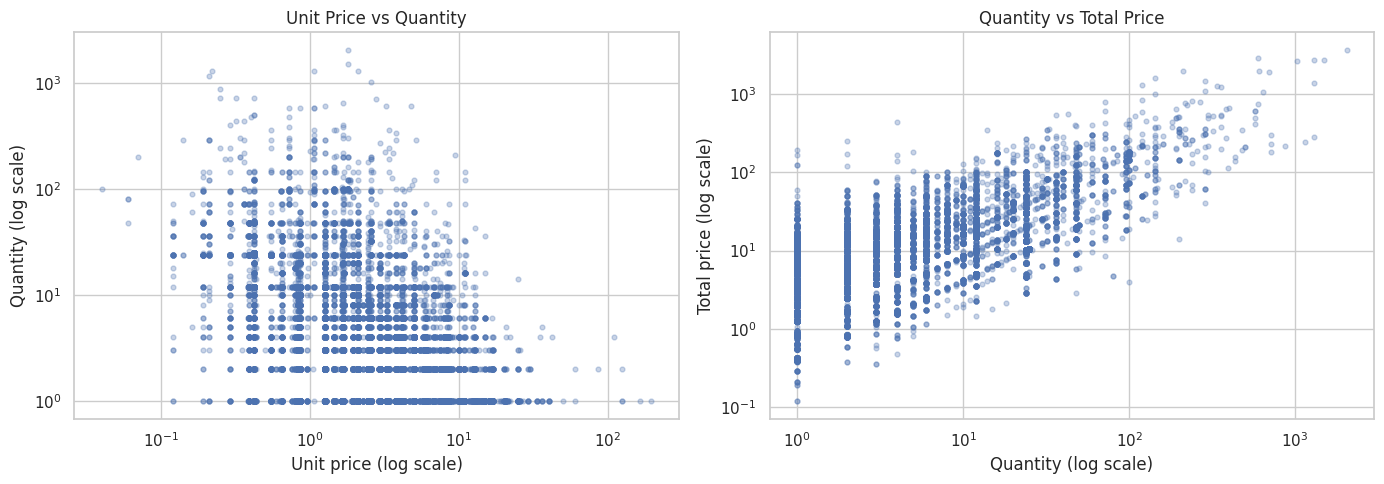

In [34]:
# Step 8: Scatter plots (sampled, log-log axes)

# Random sample for readability; random_state makes it reproducible
sample = genuine.sample(20000, random_state=42)

# Sanity check: log scale needs strictly positive values
print(sample[["quantity", "unit_price", "total_price"]].min())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: unit price (x) vs quantity (y)
axes[0].scatter(sample["unit_price"], sample["quantity"], alpha=0.3, s=12)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Unit price (log scale)")
axes[0].set_ylabel("Quantity (log scale)")
axes[0].set_title("Unit Price vs Quantity")

# Plot 2: quantity (x) vs line total (y)
axes[1].scatter(sample["quantity"], sample["total_price"], alpha=0.3, s=12)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Quantity (log scale)")
axes[1].set_ylabel("Total price (log scale)")
axes[1].set_title("Quantity vs Total Price")

plt.tight_layout()
plt.show()

**Observations (Step 8):**
- The sample minimums are all positive (quantity 1, unit price 0.04, total price 0.12), so log scales are valid.
- **Unit price vs. quantity:** The points form a downward-sloping triangle. Cheap items (roughly under 5) are sold in a wide range of quantities, including bulk lines of 100+ units. Expensive items almost never appear with high quantities, so the upper-right corner is empty. This matches the negative Spearman correlation (-0.41) seen in the heatmap. Because the pattern is a boundary rather than a tight line, it also explains why the linear Pearson value was only -0.09.
- Dense horizontal bands at low quantities and vertical stripes at certain prices show that quantity and unit price take common discrete values (for example, pack sizes and standard price points).
- **Quantity vs. total price:** The points form a clear upward band, and the vertical stripes reflect the common order quantities. The width of the band at each quantity comes from differences in unit price. This relationship is partly mechanical, because total price = quantity x unit price, so it is not an independent finding.
- The main takeaway is that large line totals come mostly from high quantities of low-priced items, not from expensive items. This is a visual pattern from a 20,000-row sample and does not prove causation.

## Step 9: Key Insights and Business Recommendations

**Insight 1: Late-year revenue growth is driven by order volume, not order value.**
Monthly revenue rose from about 0.51M-0.74M (Jan-Aug 2011) to 1.03M in September, 1.10M in October and 1.45M in November (the highest month). Invoices grew from 1,339 in August to 2,751 in November, while revenue per invoice stayed roughly flat, and box plots showed similar median order values across months. September to November together contribute about 36% of revenue. December 2010 (the first month of the data) also shows high revenue (775,638) and 1,550 invoices, which is consistent with a year-end seasonal peak.
*Recommendation:* Plan inventory, staffing and marketing around the September-November surge, and focus campaigns on bringing in more orders rather than on raising basket size.

**Insight 2: Revenue depends heavily on the UK, while a few other markets are driven by a small number of large invoices.**
The UK generates 84.72% of revenue (8.44M from 17,898 invoices, about 472 per invoice). Netherlands (93 invoices, about 3,053 per invoice), Australia (56 invoices, about 2,466 per invoice) and Japan (19 invoices, about 1,969 per invoice) have far fewer but much larger invoices.
*Recommendation:* Protect UK service levels, and treat these markets as wholesale-style accounts with dedicated account management and bulk-pricing offers. Their small invoice counts mean results can swing with one or two customers.

**Insight 3: Best-selling products by units differ from those by revenue, and customer revenue is concentrated.**
The top product by revenue is REGENCY CAKESTAND 3 TIER (174,157; 13,851 units), while the top products by units are POPCORN HOLDER (56,898 units, 51,334 revenue) and WORLD WAR 2 GLIDERS ASSTD DESIGNS (54,951 units, 13,814 revenue). Only 5 products appear in both top-10 lists. The top 10 customers account for 16.63% of known-customer revenue. Scatter plots show that large quantities occur mainly for low-priced items.
*Recommendation:* Use high-volume, low-price items for traffic and bulk deals, and promote high-revenue items for margin. Retain top customers with loyalty or account programs, and distinguish bulk buyers (for example, customer 12415: 124,565 in 20 invoices) from frequent buyers (customer 14911: 136,162 in 198 invoices).

**Insight 4: Revenue peaks between 10:00 and 15:59.**
Hourly revenue is highest in this window, with the peak around 12:00.
*Recommendation:* Schedule promotions, email campaigns and customer support coverage for these hours, and run maintenance outside them.

## Conclusions

This analysis explored 522,534 genuine order lines from the cleaned Online Retail dataset. Quantity, unit price and line total are all strongly right-skewed, so medians describe a typical order better than means. Revenue is concentrated in the UK, in the September-November period and in a small group of customers, and large line totals are driven mainly by high quantities of low-priced items.

**Limitations:**
- The data covers only about one year, and December 2011 is incomplete (data ends on 2011-12-09), so seasonality cannot be separated from business growth.
- About 25.1% of rows have no customer ID, so customer-level findings cover known customers only.
- One large order line (invoice 556444, 38,970) was removed because it was reversed minutes later by a manual entry (C556445) that Task 1 had removed as a non-product row. This is an inconsistency between Task 1 and Task 2 and should be handled consistently in future cleaning.
- Findings are descriptive. Correlations and scatter patterns do not prove causation.